# Does breathing encode social rank? Rank decoder, Jan + Jul 2026 cagemate recordings

**Sequioa Smith, Padilla-Coreano lab. Written for Thomas to check every step and decision.**

**Question.** During a cagemate interaction, can the subject's breathing tell whether it **outranks** its cagemate or is
**outranked**? Rank is treated as an internal *state*, so the decoder uses fixed time windows, not behavior bouts.

**How to read this notebook.** Each section states the decision first (in words, with the reason), then the code that applies it,
then the result. All functions come from `scripts/rank_decoder_2026.py`, so this notebook and the script cannot drift apart.
Run top to bottom with the **biopipeline-env** kernel. The permutation tests are the slow part (set `N_PERM` below).

| Step | What | Decision |
|---|---|---|
| 1 | Recordings and exclusions | 2026 cagemate recordings; 10.2, 11.3 dropped (bad signal); Jun 2025 kept out (headstage, half the movement) |
| 2 | Rank labels | Tube-test sheet via `src/r34_ranks.py`, never file names |
| 3 | Breaths | Hand-reviewed breaths stored in the shared H5 (`respiration/breaths/reviewed`) |
| 4 | Windows | Fixed 3 s, non-overlapping, clean signal only; BORIS only *tags* them |
| 5 | Descriptive check | Rate by relative rank, mixed model with mouse as random effect |
| 6 | Locomotion check | Speed from SLEAP, so breathing results can be checked against movement |
| 7-9 | Decoder | Logistic regression, then RBF SVM; leave one cage out; tuning inside training cages; shuffled-label null |
| 10 | Controls | Rate only, locomotion only, breathing + locomotion, each cohort alone, all windows |

In [1]:
# ---- parameters -------------------------------------------------------------------------------------------
N_PERM = 100          # shuffled-label repeats per analysis (whole pipeline incl. tuning). Manuscript run: 200+ via the script.
RUN_CONTROLS = True   # False = main analyses only (faster)

In [2]:
import sys, json, warnings; warnings.filterwarnings('ignore')
from pathlib import Path
ROOT = Path.cwd()
for _ in range(6):
    if (ROOT/'scripts'/'rank_decoder_2026.py').exists(): break
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT/'scripts'), str(ROOT/'src')]
import numpy as np, pandas as pd, h5py, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import display, Markdown, Image
import rank_decoder_2026 as RD
from r34_ranks import RANKS, CAGEMATE_SESSIONS, session_info
OUT = RD.OUT/'notebook_run'; OUT.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
COL = {'higher': '#D55E00', 'lower': '#0072B2'}; MK = {'Jan 2026': 'o', 'Jul 2026': 'D'}
def tidy(ax):
    ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', color='#e5e5e5', lw=.6); ax.set_axisbelow(True)
print('repo:', ROOT); print('data:', RD.MS); print('outputs:', OUT)

repo: C:\Users\sjs93\OneDrive\Documents\GitHub\respiratory_pilot
data: C:\Users\sjs93\UF Dropbox\Sequioa Smith\Padilla-Coreano Lab\2026\respiration_valence_isolation_manuscript_SSmith
outputs: C:\Users\sjs93\UF Dropbox\Sequioa Smith\Padilla-Coreano Lab\2026\respiration_valence_isolation_manuscript_SSmith\07_rank_decoder\notebook_run


## 1. Recordings and exclusions

**Decision.** Use every Jan 2026 and Jul 2026 cagemate recording with a rank label, except:

| Recording | Why |
|---|---|
| `10_2_d_CM_10_1_s` (Jul 2026) | Unusable respiration: cannula bled at flush, small in/out signal; review needed ~30 fast added breaths per minute (EXCLUSIONS_LOG, 2026-11-24) |
| `11_3_s_CM_11_4_d` (Jul 2026) | Unusable respiration: air had to be pushed; 394 hand-added breaths raise the rate by ~0.7 Hz (EXCLUSIONS_LOG, 2026-11-24) |
| `13_2_d_CM_13_1_s_..._181321` (Jul 2026) | Second 13.2 recording that day; the first (`..._111038`) is used until decided |

**Jun 2025 is not in the decoder.** Those mice carried the Sprite headstage and moved about half as much as 2026 mice
(26% vs 53-60% of time moving), so pooling would mix rank with hardware and movement. Jun 2025 is analysed separately.

**Not reviewed / not used:** the Jan 5 2026 clean-cage baselines (separate recordings, no cagemate, not hand-reviewed).

**Differs from Thomas's EXCLUSIONS_LOG (to discuss):** his log predates the 2026 cohorts ("cohort 2: no baseline;
cohort 3: recorded later"). The decoder now uses both; Jan 2026 has no baseline, which the decoder does not need.

In [3]:
S = pd.DataFrame([session_info(s) for s, v in CAGEMATE_SESSIONS.items() if v[0] in RD.COHORT_DIR])
S['used'] = ~S.session_id.isin(RD.EXCLUDE)
S['why_not'] = S.session_id.map(RD.EXCLUDE).fillna('')
display(S[['session_id', 'cohort', 'cage', 'subject', 'partner', 'subject_rank', 'partner_rank', 'relative', 'sex', 'used', 'why_not']])
print(S[S.used].groupby(['cohort', 'relative']).size().rename('recordings'))

,session_id,cohort,cage,subject,partner,subject_rank,partner_rank,relative,sex,used,why_not
0,1_1_d_cm_1_2_i_20260106_134350,Jan 2026,1,1.1,1.2,2,1,lower,F,True,
1,1_1_i_cm_1_3_s_20260107_163611,Jan 2026,1,1.1,1.3,2,3,higher,F,True,
2,1_2_d_cm_1_3_s_20260108_114416,Jan 2026,1,1.2,1.3,1,3,higher,F,True,
3,1_3_s_1_2_d_20260107_165340,Jan 2026,1,1.3,1.2,3,1,lower,F,True,
4,1_3_s_cm_1_1_i_20260106_122823,Jan 2026,1,1.3,1.1,3,2,lower,F,True,
5,2_1_d_cm_2.3_i_20260106_105109,Jan 2026,2,2.1,2.3,1,2,higher,F,True,
6,2_1_d_cm_2_2_s_20260108_112426,Jan 2026,2,2.1,2.2,1,3,higher,F,True,
7,2_2_s_cm_2_1_d_20260108_120453,Jan 2026,2,2.2,2.1,3,1,lower,F,True,
8,2_2_s_cm_2_3_i_20260106_132549,Jan 2026,2,2.2,2.3,3,2,lower,F,True,
9,3_1_i_cm_3_2_d_20260106_115157,Jan 2026,3,3.1,3.2,2,1,lower,F,True,


cohort    relative
Jan 2026  higher      12
          lower       12
Jul 2026  higher       3
          lower        5
Name: recordings, dtype: int64


## 2. Rank labels

**Decision.** Rank comes from the tube-test sheet, copied into `src/r34_ranks.py` (`RANKS`, 1 = most dominant within the cage).
The label is **relative**: `higher` = subject outranks this cagemate, `lower` = subject is outranked.
**File names are never used for rank**: the d / i / s letters are wrong in several names (e.g. `1_1_d_cm_1_2_i`: the sheet ranks
1.2 above 1.1). Intermediate mice in Jan 2026 meet one higher- and one lower-ranked cagemate, so they appear with both labels.

In [4]:
print('Ranks used (1 = most dominant):')
for c in RD.COHORT_DIR: print(f'  {c}:', ', '.join(f'{m}={r}' for m, r in sorted(RANKS[c].items(), key=lambda x: (int(x[0].split(".")[0]), x[1]))))
both = S[S.used].groupby('subject').relative.agg(lambda s: set(s) >= {'higher', 'lower'})
print('\nMice recorded with both a higher- and a lower-ranked cagemate:', ', '.join(both[both].index))

Ranks used (1 = most dominant):
  Jan 2026: 1.2=1, 1.1=2, 1.3=3, 2.1=1, 2.3=2, 2.2=3, 3.2=1, 3.1=2, 3.3=3, 4.2=1, 4.3=2, 4.1=3, 5.2=1, 5.1=2, 5.3=3, 6.2=1, 6.3=2, 7.1=1, 7.2=2, 8.1=1, 8.2=2
  Jul 2026: 9.4=1, 9.2=2, 9.3=3, 9.1=4, 10.2=1, 10.4=2, 10.3=3, 10.1=4, 11.4=1, 11.2=2, 11.3=3, 12.2=1, 12.3=2, 12.4=3, 13.2=1, 13.4=2, 13.3=3, 13.1=4, 14.1=1, 14.2=2, 14.4=3, 14.3=4

Mice recorded with both a higher- and a lower-ranked cagemate: 1.1, 3.1, 5.1


## 3. Hand-reviewed breaths (from the shared H5)

**Decision.** Breaths come from `respiration/breaths/reviewed` in each shared H5 (`01_shared_h5/`). That group is written by
`scripts/apply_review_to_shared_h5.py` from the review files and is rebuilt exactly each time it is rerun:
final breaths = detected peaks − removed + added, minus anything in a stretch the reviewer marked as bad signal
(`reviewer_excluded`). `review_stage` says whether Sequioa's final check (FINAL) is done or only the first review (returned).
Format: `docs/r34_shared_h5_format.txt`.

In [5]:
rows = []
for sid in S[S.used].session_id:
    info = session_info(sid)
    with h5py.File(RD.H5/RD.COHORT_DIR[info['cohort']]/f'{sid}.h5', 'r') as h:
        g = h['respiration/breaths/reviewed']; src = g['breath_source'][:].astype(str)
        rows.append(dict(session_id=sid, cohort=info['cohort'], review_stage=g.attrs['review_stage'], breaths=len(src),
                         added=(src == 'added').sum(), bad_signal_s=round(float(g.attrs['excluded_s']), 1),
                         recording_s=round(len(h['respiration/preprocessed/time_s']) / 100, 1)))
B = pd.DataFrame(rows); display(B)
print(B.review_stage.value_counts().to_string())

,session_id,cohort,review_stage,breaths,added,bad_signal_s,recording_s
0,1_1_d_cm_1_2_i_20260106_134350,Jan 2026,FINAL,5127,92,15.5,610.3
1,1_1_i_cm_1_3_s_20260107_163611,Jan 2026,FINAL,5459,147,0.0,614.4
2,1_2_d_cm_1_3_s_20260108_114416,Jan 2026,FINAL,4760,19,0.0,603.5
3,1_3_s_1_2_d_20260107_165340,Jan 2026,FINAL,4387,38,13.9,608.8
4,1_3_s_cm_1_1_i_20260106_122823,Jan 2026,FINAL,4945,48,0.0,604.7
5,2_1_d_cm_2.3_i_20260106_105109,Jan 2026,FINAL,5112,86,0.0,603.5
6,2_1_d_cm_2_2_s_20260108_112426,Jan 2026,returned,5284,87,0.0,614.6
7,2_2_s_cm_2_1_d_20260108_120453,Jan 2026,returned,5391,149,0.0,609.4
8,2_2_s_cm_2_3_i_20260106_132549,Jan 2026,returned,5453,78,0.0,613.5
9,3_1_i_cm_3_2_d_20260106_115157,Jan 2026,returned,5314,180,8.5,605.6


review_stage
FINAL       18
returned    14


## 4. Fixed 3 s windows, tagged by BORIS

**Decisions.**
- **Fixed 3 s, non-overlapping windows** over all cagemate time (PI decision: rank and valence are states; Janke et al. 2022 used
  behavior bouts only because they were classifying behaviors).
- A window is used **only if it contains no reviewer-marked bad signal** (all usable windows are kept for modeling; rate *plots*
  elsewhere use an equal 180 s of clean signal per recording).
- **BORIS only tags windows**, it does not create them: `none` = no investigation by either mouse;
  `subject investigating`, `being investigated`, `both`. Investigation = facial / body / anogenital sniffing, allogrooming, chasing
  (digging and self-grooming do not count). **Main analysis = `none` windows** (state outside investigation; PI: e.g. the bully
  lowers breathing outside investigation). BORIS times are on the recording clock (Trodes frame times; see
  `scripts/clean_boris_for_manuscript.py`).
- Jul 2026 recordings start with a 5 min baseline (no cagemate); only cagemate time is used.

In [6]:
rows = []
for sid in S[S.used].session_id:
    w, stage = RD.windows_for(sid); rows += w
W = pd.DataFrame(rows); W = W[W.relative.isin(['higher', 'lower'])].copy(); W['y'] = (W.relative == 'lower').astype(int)
W.to_csv(OUT/'windows_2026.csv', index=False)
print(f'{len(W)} windows from {W.session_id.nunique()} recordings, {W.subject.nunique()} mice, {W.cage.nunique()} cages')
display(pd.crosstab(W.cohort, W.tag, margins=True))

5341 windows from 32 recordings, 25 mice, 12 cages


tag,being investigated,both,none,subject investigating,All
cohort,,,,,
Jan 2026,583,646,3011,329,4569
Jul 2026,159,144,327,142,772
All,742,790,3338,471,5341


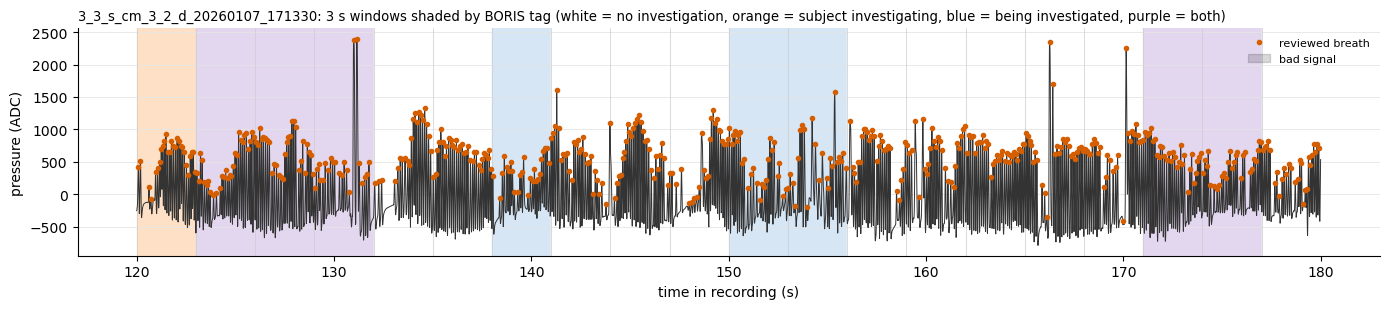

In [7]:
# One example recording: 60 s of breathing with reviewed breaths, bad signal and window tags
sid = '3_3_s_cm_3_2_d_20260107_171330'; info = session_info(sid)
with h5py.File(RD.H5/RD.COHORT_DIR[info['cohort']]/f'{sid}.h5', 'r') as h:
    y = h['respiration/preprocessed/pressure'][:]; t = h['respiration/preprocessed/time_s'][:]
    g = h['respiration/breaths/reviewed']; bi = g['breath_index'][:]; bad = g['reviewer_excluded'][:]
w = W[W.session_id == sid]; t0 = w.start_s.iloc[40]; s0, s1 = int(np.searchsorted(t, t0)), int(np.searchsorted(t, t0 + 60))
TAGC = {'none': '#ffffff', 'subject investigating': '#fde0c5', 'being investigated': '#d6e6f5', 'both': '#e3d7ef'}
fig, ax = plt.subplots(figsize=(14, 3.2))
for r in w[(w.start_s >= t0) & (w.start_s < t0 + 60)].itertuples():
    ax.axvspan(r.start_s, r.start_s + 3, color=TAGC[r.tag], zorder=0); ax.axvline(r.start_s, color='#ccc', lw=.5)
ax.plot(t[s0:s1] - t[0], y[s0:s1], color='#333', lw=.7); b = bi[(bi >= s0) & (bi < s1)]
ax.plot(t[b] - t[0], y[b], 'o', ms=3, color='#D55E00', label='reviewed breath')
ax.fill_between(t[s0:s1] - t[0], y[s0:s1].min(), y[s0:s1].max(), where=bad[s0:s1], color='k', alpha=.15, label='bad signal')
ax.set_xlabel('time in recording (s)'); ax.set_ylabel('pressure (ADC)'); tidy(ax)
ax.set_title(f'{sid}: 3 s windows shaded by BORIS tag (white = no investigation, orange = subject investigating, '
             'blue = being investigated, purple = both)', loc='left', fontsize=9.5)
ax.legend(loc='upper right', fontsize=8, frameon=False); plt.tight_layout(); plt.savefig(OUT/'example_windows.png', dpi=130); plt.show()

## 5. Descriptive check: is the outranked mouse breathing faster?

**Decision (planned before looking):** compare the **last 5 min of cagemate time**, matched to the 5 min baseline length.
Whole cagemate time is shown as a check. Each recording's rate = mean window rate (clean windows only).
Mixed model: `rate ~ outranked + cohort`, random intercept per mouse (mice appear in more than one recording).

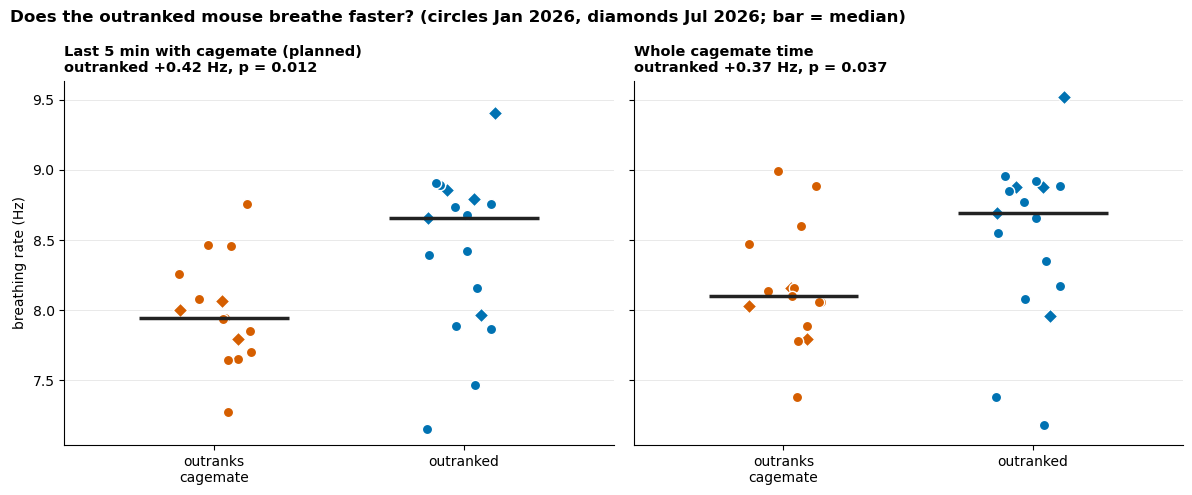

In [8]:
W['t_from_end'] = W.groupby('session_id').start_s.transform('max') - W.start_s
rec = lambda d: d.groupby('session_id').agg(rate=('rate', 'mean'), y=('y', 'first'), cohort=('cohort', 'first'),
                                            subject=('subject', 'first'), relative=('relative', 'first')).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, (title, d) in zip(axs, [('Last 5 min with cagemate (planned)', W[W.t_from_end < 300]), ('Whole cagemate time', W)]):
    R = rec(d); R['mouse'] = R.cohort + ' ' + R.subject
    m = smf.mixedlm('rate ~ y + cohort', R, groups=R.mouse).fit(reml=True)
    rng = np.random.default_rng(0)
    for r in R.itertuples(): ax.scatter(r.y + rng.uniform(-.15, .15), r.rate, marker=MK[r.cohort], color=COL[r.relative], s=55, edgecolor='white', zorder=3)
    for k in (0, 1): ax.hlines(R[R.y == k].rate.median(), k - .3, k + .3, color='#222', lw=2.5, zorder=4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(['outranks\ncagemate', 'outranked']); ax.set_xlim(-.6, 1.6); tidy(ax)
    ax.set_title(f'{title}\noutranked {m.params["y"]:+.2f} Hz, p = {m.pvalues["y"]:.3f}', loc='left', fontsize=10.5, weight='bold')
axs[0].set_ylabel('breathing rate (Hz)')
fig.suptitle('Does the outranked mouse breathe faster? (circles Jan 2026, diamonds Jul 2026; bar = median)', x=.01, ha='left', weight='bold')
plt.tight_layout(); plt.savefig(OUT/'rate_by_rank.png', dpi=130); plt.show()

## 6. Locomotion check

**Why.** Breathing rises with movement. If outranked mice simply move more, a breathing decoder could be reading movement.
Speed = both mice's center speed from SLEAP (identity-free, so uncorrected tracks can be used), in body lengths per second
(camera zoom differs between cohorts). One recording (`2_1_d_cm_2.3_i`) has no SLEAP tracking.
The cohort comparison that kept Jun 2025 out of the decoder is in `04_sleap/velocity_by_cohort.png` (shown below).

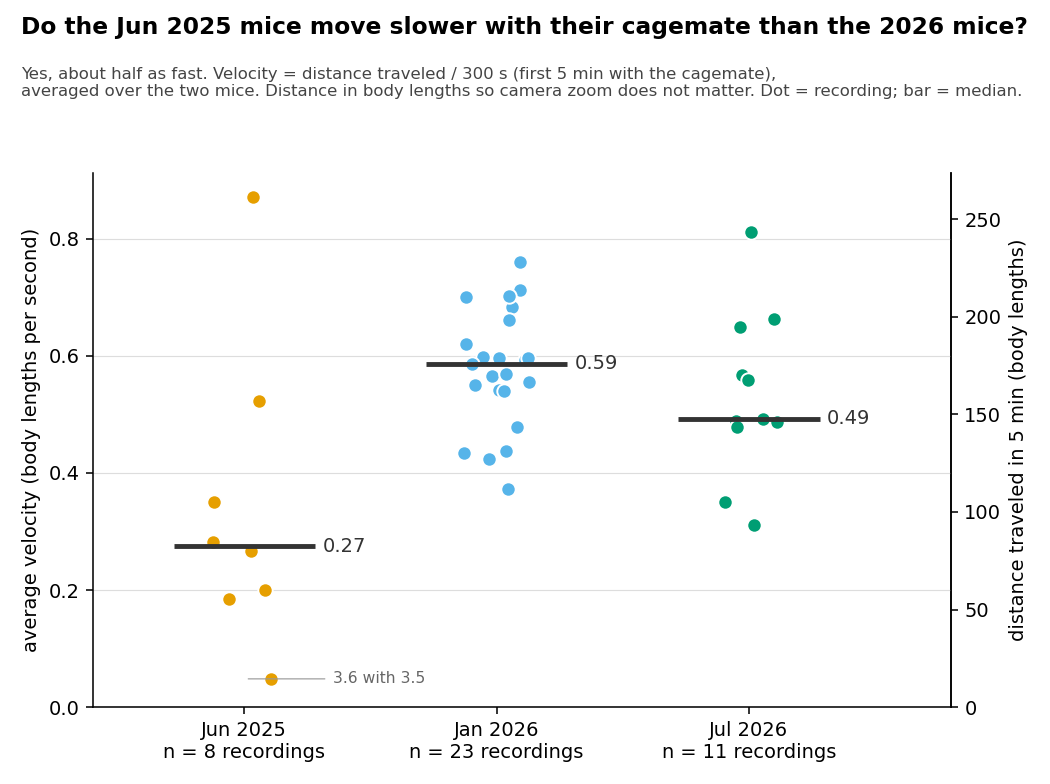

C:\Users\sjs93\anaconda3\envs\biopipeline-env\lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


**Within 2026: do outranked mice (and their cagemates) move more?** speed difference +0.023 body lengths/s, p = 0.611 (31 recordings). Decoders with locomotion are in section 10.

speed  moving
cohort   y                       
Jan 2026 outranks   0.643   0.590
         outranked  0.698   0.594
Jul 2026 outranks   0.493   0.530
         outranked  0.523   0.516

In [9]:
p = RD.MS/'04_sleap/velocity_by_cohort.png'
if p.exists(): display(Image(filename=str(p), width=520))
R = W[W.speed_mean.notna()].groupby('session_id').agg(speed=('speed_mean', 'mean'), moving=('frac_moving', 'mean'), y=('y', 'first'),
                                                       cohort=('cohort', 'first'), subject=('subject', 'first')).reset_index()
R['mouse'] = R.cohort + ' ' + R.subject
m = smf.mixedlm('speed ~ y + cohort', R, groups=R.mouse).fit(reml=True)
display(Markdown(f'**Within 2026: do outranked mice (and their cagemates) move more?** speed difference {m.params["y"]:+.3f} body lengths/s, '
                 f'p = {m.pvalues["y"]:.3f} ({len(R)} recordings). Decoders with locomotion are in section 10.'))
display(R.groupby(['cohort', 'y'])[['speed', 'moving']].median().rename(index={0: 'outranks', 1: 'outranked'}, level=1).round(3))

## 7. Breathing features (per 3 s window)

| Feature | Meaning |
|---|---|
| `rate` | breaths / 3 s, in Hz |
| `ibi_mean`, `ibi_sd`, `ibi_cv`, `ibi_min`, `ibi_max` | inter-breath intervals inside the window |
| `frac_fast` | share of intervals < 125 ms (> 8 Hz, sniffing) |
| `amp_cv` | breath amplitude variability (amplitude = peak minus the trough since the previous breath) |
| `amp_rel_mean`, `amp_rel_sd` | amplitude relative to the recording's median amplitude |

**Decision on amplitude:** raw amplitude is *not* used, because amplifier gain differs between mice (500 vs 1000) and cannula
placement differs; only amplitude relative to the same recording, or its CV, is used.
Thomas's 28 BreathMetrics features need inhale/exhale onsets; they can be added once the reviewed breaths are used for onsets.

In [10]:
Z = W[W.tag == 'none'].copy()
for c in Z.cohort.unique():                       # standardize within cohort just for this summary
    i = Z.cohort == c; Z.loc[i, RD.BREATH] = (Z.loc[i, RD.BREATH] - Z.loc[i, RD.BREATH].mean()) / Z.loc[i, RD.BREATH].std()
F = Z.groupby(['session_id', 'y'])[RD.BREATH].mean().groupby('y').mean().T
F.columns = ['outranks', 'outranked']; F['difference'] = F.outranked - F.outranks
display(F.round(3).sort_values('difference'))
print('Values are within-cohort z-scores averaged per recording (no-investigation windows).')

,outranks,outranked,difference
ibi_mean,0.146,-0.107,-0.253
ibi_min,0.101,-0.073,-0.174
ibi_sd,0.074,-0.055,-0.129
ibi_max,0.059,-0.042,-0.101
ibi_cv,0.039,-0.032,-0.071
amp_cv,-0.036,-0.000,0.036
amp_rel_sd,-0.066,0.011,0.077
amp_rel_mean,-0.057,0.023,0.079
frac_fast,-0.144,0.110,0.254
rate,-0.151,0.113,0.264


Values are within-cohort z-scores averaged per recording (no-investigation windows).


## 8. Decoder design (all decisions)

- **Unit of prediction:** the 3 s window; a recording's prediction = **mean decision value of its windows**.
  The main number is the **recording-level AUC** (does the recording score separate outranked from outranking subjects?).
- **Held-out data: leave one cage out** (12 cages). A cage's recordings are never in training when they are tested, so the
  decoder must generalize to new mice and new pairs.
- **Cohort guard (PI):** features are standardized **within each cohort**, with means/SDs from the training recordings only;
  training weights give every cohort x label group equal weight. Within-cohort decoders are reported as well.
- **Models:** logistic regression (linear baseline, like the earlier rate analysis), then RBF SVM (non-linear).
- **Tuning** happens **inside the training cages only** (3 folds grouped by cage, scored by recording-level AUC).
  Logistic C ∈ {0.01, 0.1, 1, 10}; SVM C ∈ {0.3, 3} x gamma ∈ {0.5, 2} / n_features.
- **Null:** recording labels are shuffled within cohort and the **entire** pipeline (including tuning) is rerun;
  p = (1 + number of shuffles ≥ observed) / (1 + number of shuffles).
- **95% CI:** cluster bootstrap over cages of the held-out recording scores.

In [11]:
none = W[W.tag == 'none']; sp = none[none.speed_mean.notna()]
plan = [('Main: no-investigation windows', none, 'logistic', RD.BREATH),
        ('Main: no-investigation windows', none, 'svm_rbf', RD.BREATH)]
if RUN_CONTROLS:
    plan += [('All windows', W, 'logistic', RD.BREATH), ('All windows', W, 'svm_rbf', RD.BREATH),
             ('Jan 2026 only', none[none.cohort == 'Jan 2026'], 'svm_rbf', RD.BREATH),
             ('Jul 2026 only', none[none.cohort == 'Jul 2026'], 'svm_rbf', RD.BREATH),
             ('Rate only', none, 'logistic', ['rate']),
             ('Locomotion only (control)', sp, 'svm_rbf', RD.SPEED),
             ('Breathing, windows with locomotion', sp, 'svm_rbf', RD.BREATH),
             ('Breathing + locomotion', sp, 'svm_rbf', RD.BREATH + RD.SPEED)]
print(len(plan), 'analyses x', N_PERM, 'shuffles each')

10 analyses x 100 shuffles each


## 9. Run the decoders

This cell is the slow one (minutes per analysis; each shuffle reruns the whole pipeline with tuning).

In [12]:
import time
results, recs, nulls, imps = [], [], {}, []
for name, D, model, feats in plan:
    t0 = time.time()
    res, R, null, imp = RD.analysis(name, D, model, feats, N_PERM)
    results.append(res); recs.append(R); imps.append(imp); nulls[(name, model)] = null
    print(f"{name:38s} {model:9s} AUC {res['rec_auc']:.2f} [{res['ci_low']:.2f}, {res['ci_high']:.2f}]  null {res['null_mean']:.2f}  "
          f"p = {res['p']:.3f}   ({(time.time() - t0) / 60:.1f} min)", flush=True)
RES = pd.DataFrame(results); RES.to_csv(OUT/'decoder_results.csv', index=False)
pd.concat(recs).to_csv(OUT/'heldout_recording_scores.csv'); pd.concat(imps).to_csv(OUT/'feature_importance.csv', index=False)
display(RES[['analysis', 'model', 'features', 'rec_auc', 'ci_low', 'ci_high', 'p', 'null_mean', 'rec_acc', 'win_auc',
             'auc_Jan', 'auc_Jul', 'n_rec', 'n_mice', 'n_cages', 'n_win', 'params']].round(3))

Main: no-investigation windows         logistic  AUC 0.65 [0.52, 0.80]  null 0.47  p = 0.089   (1.4 min)


Main: no-investigation windows         svm_rbf   AUC 0.73 [0.58, 0.88]  null 0.47  p = 0.030   (19.0 min)


All windows                            logistic  AUC 0.61 [0.46, 0.78]  null 0.48  p = 0.178   (1.5 min)


All windows                            svm_rbf   AUC 0.72 [0.55, 0.89]  null 0.46  p = 0.030   (47.9 min)


Jan 2026 only                          svm_rbf   AUC 0.57 [0.47, 0.72]  null 0.47  p = 0.297   (9.0 min)


Jul 2026 only                          svm_rbf   AUC 0.80 [0.25, 1.00]  null 0.47  p = 0.267   (0.3 min)


Rate only                              logistic  AUC 0.69 [0.55, 0.86]  null 0.48  p = 0.050   (1.0 min)


Locomotion only (control)              svm_rbf   AUC 0.49 [0.34, 0.62]  null 0.47  p = 0.485   (16.6 min)


Breathing, windows with locomotion     svm_rbf   AUC 0.72 [0.55, 0.87]  null 0.47  p = 0.040   (17.4 min)


Breathing + locomotion                 svm_rbf   AUC 0.64 [0.48, 0.79]  null 0.46  p = 0.089   (16.4 min)


,analysis,model,features,rec_auc,ci_low,ci_high,p,null_mean,rec_acc,win_auc,auc_Jan,auc_Jul,n_rec,n_mice,n_cages,n_win,params
0,Main: no-investigation windows,logistic,10 features,0.651,0.518,0.801,0.089,0.473,0.656,0.529,0.618,0.800,32,25,12,3338,"{""{\""C\"": 0.01}"": 8, ""{\""C\"": 1}"": 2, ""{\""C\"":..."
1,Main: no-investigation windows,svm_rbf,10 features,0.733,0.580,0.883,0.030,0.469,0.719,0.539,0.597,1.000,32,25,12,3338,"{""{\""C\"": 3, \""g\"": 2}"": 7, ""{\""C\"": 0.3, \""g\..."
2,All windows,logistic,10 features,0.608,0.458,0.781,0.178,0.485,0.562,0.528,0.618,0.800,32,25,12,5341,"{""{\""C\"": 0.01}"": 9, ""{\""C\"": 0.1}"": 1, ""{\""C\..."
3,All windows,svm_rbf,10 features,0.718,0.549,0.889,0.030,0.462,0.688,0.551,0.597,1.000,32,25,12,5341,"{""{\""C\"": 3, \""g\"": 2}"": 11, ""{\""C\"": 0.3, \""g..."
4,Jan 2026 only,svm_rbf,10 features,0.569,0.470,0.720,0.297,0.466,0.542,0.519,0.569,NaN,24,17,8,3011,"{""{\""C\"": 3, \""g\"": 2}"": 3, ""{\""C\"": 0.3, \""g\..."
5,Jul 2026 only,svm_rbf,10 features,0.800,0.250,1.000,0.267,0.474,0.875,0.669,NaN,0.800,8,8,4,327,"{""{\""C\"": 0.3, \""g\"": 2}"": 2, ""{\""C\"": 0.3, \""..."
6,Rate only,logistic,rate,0.694,0.551,0.863,0.050,0.483,0.688,0.550,0.646,0.933,32,25,12,3338,"{""{\""C\"": 0.01}"": 12}"
7,Locomotion only (control),svm_rbf,speed_mean+frac_moving,0.492,0.338,0.619,0.485,0.469,0.516,0.498,0.538,0.400,31,25,12,3210,"{""{\""C\"": 0.3, \""g\"": 2}"": 4, ""{\""C\"": 3, \""g\..."
8,"Breathing, windows with locomotion",svm_rbf,10 features,0.718,0.549,0.870,0.040,0.467,0.742,0.534,0.568,1.000,31,25,12,3210,"{""{\""C\"": 3, \""g\"": 2}"": 6, ""{\""C\"": 0.3, \""g\..."
9,Breathing + locomotion,svm_rbf,12 features,0.643,0.483,0.792,0.089,0.462,0.548,0.528,0.606,0.800,31,25,12,3210,"{""{\""C\"": 0.3, \""g\"": 0.5}"": 10, ""{\""C\"": 0.3,..."


## 10. Results figures

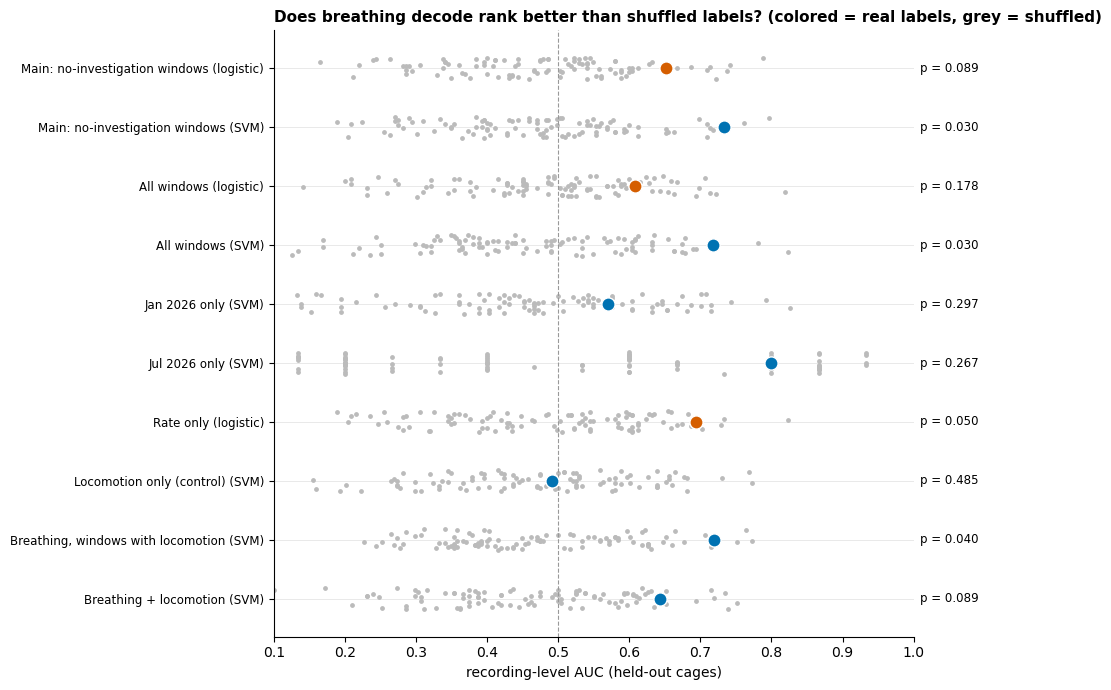

In [13]:
# Observed recording-level AUC (dot) against its shuffled-label null (grey) for every analysis
fig, ax = plt.subplots(figsize=(10, .55 * len(RES) + 1.5))
for i, r in enumerate(RES.itertuples()):
    nl = nulls[(r.analysis, r.model)]; yy = len(RES) - 1 - i
    ax.scatter(nl, yy + np.random.default_rng(i).uniform(-.18, .18, len(nl)), s=6, color='#bbb', zorder=1)
    ax.scatter(r.rec_auc, yy, s=90, color='#0072B2' if r.model == 'svm_rbf' else '#D55E00', zorder=3, edgecolor='white')
    ax.text(1.01, yy, f'p = {r.p:.3f}', va='center', fontsize=8.5, transform=ax.get_yaxis_transform())
ax.set_yticks(range(len(RES))); ax.set_yticklabels([f'{r.analysis} ({"SVM" if r.model == "svm_rbf" else "logistic"})' for r in RES.itertuples()][::-1], fontsize=8.5)
ax.axvline(.5, color='#999', lw=.8, ls='--'); ax.set_xlabel('recording-level AUC (held-out cages)'); ax.set_xlim(.1, 1); tidy(ax)
ax.set_title('Does breathing decode rank better than shuffled labels? (colored = real labels, grey = shuffled)', loc='left', fontsize=11, weight='bold')
plt.tight_layout(); plt.savefig(OUT/'decoder_vs_null.png', dpi=140); plt.show()

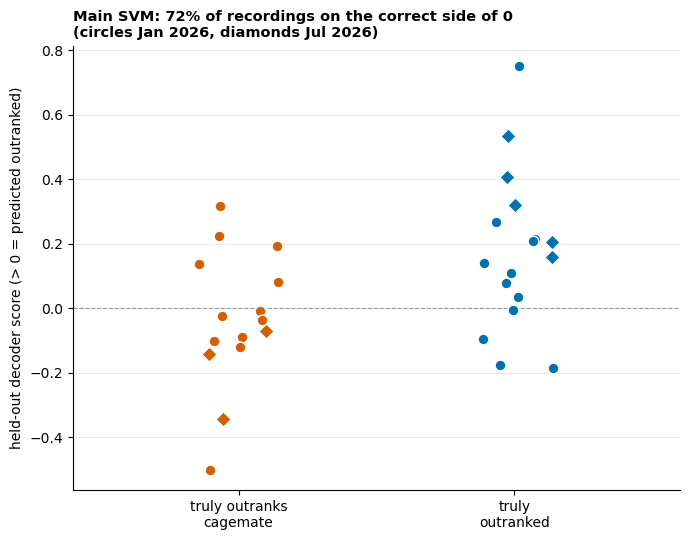

In [14]:
# Held-out scores per recording for the main SVM: does each recording land on the right side?
Rm = pd.concat(recs); Rm = Rm[(Rm.analysis == 'Main: no-investigation windows') & (Rm.model == 'svm_rbf')]
fig, ax = plt.subplots(figsize=(7, 5.5)); rng = np.random.default_rng(1)
for r in Rm.itertuples():
    ax.scatter(r.y + rng.uniform(-.15, .15), r.score, marker=MK[r.cohort], color=COL[r.relative], s=60, edgecolor='white', zorder=3)
ax.axhline(0, color='#999', lw=.8, ls='--'); ax.set_xticks([0, 1]); ax.set_xticklabels(['truly outranks\ncagemate', 'truly\noutranked']); ax.set_xlim(-.6, 1.6)
ax.set_ylabel('held-out decoder score (> 0 = predicted outranked)'); tidy(ax)
ok = ((Rm.score > 0) == (Rm.y == 1)).mean()
ax.set_title(f'Main SVM: {ok:.0%} of recordings on the correct side of 0\n(circles Jan 2026, diamonds Jul 2026)', loc='left', fontsize=10.5, weight='bold')
plt.tight_layout(); plt.savefig(OUT/'heldout_scores_main_svm.png', dpi=140); plt.show()

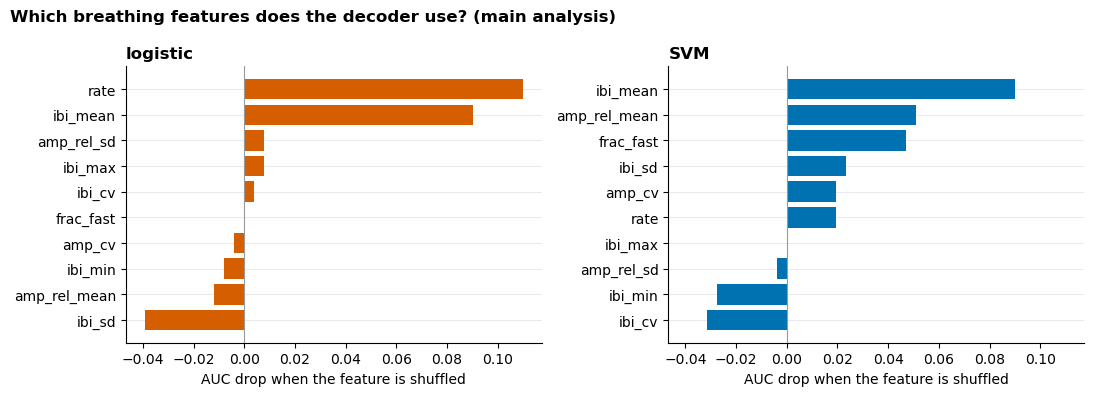

In [15]:
# Which features carry the information? Drop in recording-level AUC when one feature is shuffled in the held-out cages
I = pd.concat(imps); I = I[I.analysis == 'Main: no-investigation windows']
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, (mdl, g) in zip(axs, I.groupby('model')):
    g = g.sort_values('auc_drop'); ax.barh(g.feature, g.auc_drop, color='#0072B2' if mdl == 'svm_rbf' else '#D55E00')
    ax.axvline(0, color='#999', lw=.8); ax.set_title('SVM' if mdl == 'svm_rbf' else 'logistic', loc='left', weight='bold'); tidy(ax)
axs[0].set_xlabel('AUC drop when the feature is shuffled'); axs[1].set_xlabel('AUC drop when the feature is shuffled')
fig.suptitle('Which breathing features does the decoder use? (main analysis)', x=.01, ha='left', weight='bold')
plt.tight_layout(); plt.savefig(OUT/'feature_importance.png', dpi=140); plt.show()

## 11. Summary (written from the results above)

In [16]:
g = lambda a, m: RES[(RES.analysis == a) & (RES.model == m)].iloc[0] if ((RES.analysis == a) & (RES.model == m)).any() else None
lines = []
for m in ['logistic', 'svm_rbf']:
    r = g('Main: no-investigation windows', m)
    lines.append(f"- **{'RBF SVM' if m == 'svm_rbf' else 'Logistic regression'}**, no-investigation windows: recording AUC **{r.rec_auc:.2f}** "
                 f"(95% CI {r.ci_low:.2f}-{r.ci_high:.2f}; shuffled {r.null_mean:.2f}; p = {r.p:.3f}; {r.n_rec} recordings, {r.n_mice} mice, {r.n_cages} cages). "
                 f"Jan 2026 {r.auc_Jan:.2f}, Jul 2026 {r.auc_Jul:.2f}.")
for a, m in [('Rate only', 'logistic'), ('Locomotion only (control)', 'svm_rbf'), ('Breathing, windows with locomotion', 'svm_rbf'),
             ('Breathing + locomotion', 'svm_rbf'), ('Jan 2026 only', 'svm_rbf'), ('Jul 2026 only', 'svm_rbf'), ('All windows', 'svm_rbf')]:
    r = g(a, m)
    if r is not None: lines.append(f"- {a} ({'SVM' if m == 'svm_rbf' else 'logistic'}): AUC {r.rec_auc:.2f} [{r.ci_low:.2f}, {r.ci_high:.2f}], p = {r.p:.3f}")
stage = B.review_stage.value_counts().to_dict()
display(Markdown('\n'.join(lines) + f"\n\nReview stage of the breaths used: {stage}. Shuffles per analysis: {N_PERM}."))

- **Logistic regression**, no-investigation windows: recording AUC **0.65** (95% CI 0.52-0.80; shuffled 0.47; p = 0.089; 32 recordings, 25 mice, 12 cages). Jan 2026 0.62, Jul 2026 0.80.
- **RBF SVM**, no-investigation windows: recording AUC **0.73** (95% CI 0.58-0.88; shuffled 0.47; p = 0.030; 32 recordings, 25 mice, 12 cages). Jan 2026 0.60, Jul 2026 1.00.
- Rate only (logistic): AUC 0.69 [0.55, 0.86], p = 0.050
- Locomotion only (control) (SVM): AUC 0.49 [0.34, 0.62], p = 0.485
- Breathing, windows with locomotion (SVM): AUC 0.72 [0.55, 0.87], p = 0.040
- Breathing + locomotion (SVM): AUC 0.64 [0.48, 0.79], p = 0.089
- Jan 2026 only (SVM): AUC 0.57 [0.47, 0.72], p = 0.297
- Jul 2026 only (SVM): AUC 0.80 [0.25, 1.00], p = 0.267
- All windows (SVM): AUC 0.72 [0.55, 0.89], p = 0.030

Review stage of the breaths used: {'FINAL': 18, 'returned': 14}. Shuffles per analysis: 100.

## 12. Decisions log and open items

**Decisions made (Sequioa, with PI where noted)**
1. Rank is a state: fixed 3 s windows, not behavior bouts (PI).
2. Main analysis = windows without investigation; BORIS only tags windows (PI).
3. Cohort-balanced training plus within-cohort decoders (PI).
4. Jun 2025 kept out of the 2026 decoder: Sprite headstage and about half the locomotion.
5. Exclusions: 10.2 and 11.3 (respiration unusable), second 13.2 recording (until decided).
6. Rank from the tube-test sheet only (`src/r34_ranks.py`).
7. Breaths: hand-reviewed list in the shared H5; bad-signal stretches removed from both breaths and time.
8. Descriptive comparison window = last 5 min of cagemate time (planned to match the 5 min baseline).
9. "Baseline", not "alone", for the pre-cagemate period (the mouse was just handled and tethered).

**Open items**
- Remaining FINAL breath checks (rerun `scripts/apply_review_to_shared_h5.py`, then this notebook).
- Which 13.2 recording counts; 14.1 BORIS is being re-coded (its tags are incomplete).
- Thomas's EXCLUSIONS_LOG: add the 2026 cohorts to the rank dataset; 3.6 empty BORIS is a verified zero, not missing.
- Add BreathMetrics inhale/exhale features once onsets are computed from the reviewed breaths.
- Manuscript p-values: rerun with more shuffles (`python scripts/rank_decoder_2026.py --perm 500`).

In [17]:
info = dict(notebook='notebooks/sequioa_notebooks/rank_decoder_2026.ipynb', n_perm=N_PERM, run_controls=RUN_CONTROLS,
            excluded=RD.EXCLUDE, grid=RD.GRID, review_stage=B.set_index('session_id').review_stage.to_dict(), n_windows=len(W))
(OUT/'run_info.json').write_text(json.dumps(info, indent=1)); print('saved to', OUT)

saved to C:\Users\sjs93\UF Dropbox\Sequioa Smith\Padilla-Coreano Lab\2026\respiration_valence_isolation_manuscript_SSmith\07_rank_decoder\notebook_run
